In [1]:
import pandas as pd
df=pd.read_csv("data/NusseltdataCSV.csv")

In [2]:
df

,x1,x2,x3,x4,x5,nu
0,5.0,0.0,0.0,0.0,3477.7020,24.058300
1,5.0,0.0,0.0,0.0,6955.4040,40.439094
2,5.0,0.0,0.0,0.0,10433.1061,50.367336
3,5.0,0.0,0.0,0.0,13910.8081,60.316725
4,5.0,0.0,0.0,0.0,17388.5101,70.229644
...,...,...,...,...,...,...
121,3.5,0.5,0.0,0.0,6955.4040,43.419611
122,3.5,0.5,0.0,0.0,10433.1061,54.123641
123,3.5,0.5,0.0,0.0,13910.8081,64.855564
124,3.5,0.5,0.0,0.0,17388.5101,75.998030


In [3]:
pd.set_option('display.max_rows',126)
df

,x1,x2,x3,x4,x5,nu
0,5.0,0.0,0.00,0.0,3477.7020,24.058300
1,5.0,0.0,0.00,0.0,6955.4040,40.439094
2,5.0,0.0,0.00,0.0,10433.1061,50.367336
3,5.0,0.0,0.00,0.0,13910.8081,60.316725
4,5.0,0.0,0.00,0.0,17388.5101,70.229644
5,5.0,0.0,0.00,0.0,20866.2121,83.020652
6,5.0,0.0,0.05,1.5,3477.7020,24.555150
7,5.0,0.0,0.05,1.5,6955.4040,41.639580
8,5.0,0.0,0.05,1.5,10433.1061,53.141126
9,5.0,0.0,0.05,1.5,13910.8081,64.252202


In [4]:
miu_x1 = df['x1'].mean()
sigma_x1 = df['x1'].std()

miu_x2 = df['x2'].mean()
sigma_x2 = df['x2'].std()

miu_x3 = df['x3'].mean()
sigma_x3 = df['x3'].std()

miu_x4 = df['x4'].mean()
sigma_x4 = df['x4'].std()

miu_x5 = df['x5'].mean()
sigma_x5 = df['x5'].std()

df_normalized = df.copy() 
df_normalized['x1'] = (df['x1'] - miu_x1) / sigma_x1
df_normalized['x2'] = (df['x2'] - miu_x2) / sigma_x2
df_normalized['x3'] = (df['x3'] - miu_x3) / sigma_x3
df_normalized['x4'] = (df['x4'] - miu_x4) / sigma_x4
df_normalized['x5'] = (df['x5'] - miu_x5) / sigma_x5

df_normalized

,x1,x2,x3,x4,x5,nu
0,0.629941,-0.987511,-1.524983,-1.717719,-1.482433,24.058300
1,0.629941,-0.987511,-1.524983,-1.717719,-0.889460,40.439094
2,0.629941,-0.987511,-1.524983,-1.717719,-0.296487,50.367336
3,0.629941,-0.987511,-1.524983,-1.717719,0.296487,60.316725
4,0.629941,-0.987511,-1.524983,-1.717719,0.889460,70.229644
5,0.629941,-0.987511,-1.524983,-1.717719,1.482433,83.020652
6,0.629941,-0.987511,-0.226687,0.911017,-1.482433,24.555150
7,0.629941,-0.987511,-0.226687,0.911017,-0.889460,41.639580
8,0.629941,-0.987511,-0.226687,0.911017,-0.296487,53.141126
9,0.629941,-0.987511,-0.226687,0.911017,0.296487,64.252202



m1=-1.14 m2=-0.74 m3=3.10 m4=-1.89 m5=17.13 and Intercept(c)=59.56


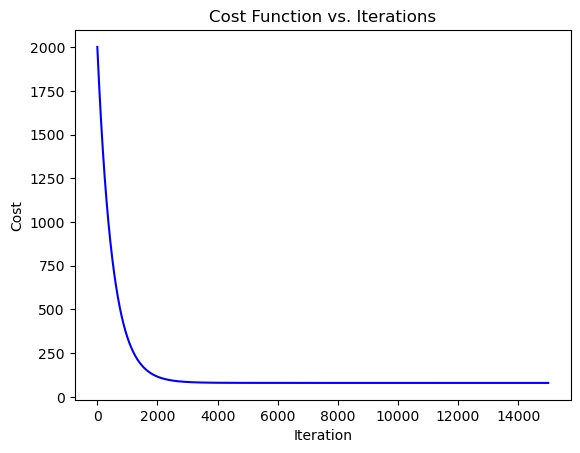

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Cost function J= c + m1*x1 + m2*x2 + m3*x3 + m4*x4 + m5*x5

x1 = df_normalized['x1'].values
x2 = df_normalized['x2'].values
x3 = df_normalized['x3'].values
x4 = df_normalized['x4'].values
x5 = df_normalized['x5'].values

y = df_normalized['nu'].values

cost_history = []  

def gradient_descent(x1,x2,x3,x4,x5):
    m1_curr=m2_curr=m3_curr=m4_curr=m5_curr=c_curr=0
    iterations=15000
    n=len(x1)
    learning_rate=0.001

    for i in range(iterations):
        y_predicted = c_curr + m1_curr*x1 + m2_curr*x2 + m3_curr*x3 + m4_curr*x4 + m5_curr*x5

        cost = (1/(2*n)) * np.sum((y_predicted - y) ** 2)
        cost_history.append(cost)

        c_d = (1/n) * np.sum(y_predicted - y)
        m1_d = (1/n) * np.sum((y_predicted - y) * x1)
        m2_d = (1/n) * np.sum((y_predicted - y) * x2)
        m3_d = (1/n) * np.sum((y_predicted - y) * x3)
        m4_d = (1/n) * np.sum((y_predicted - y) * x4)
        m5_d = (1/n) * np.sum((y_predicted - y) * x5)

        c_curr = c_curr - learning_rate * c_d
        m1_curr = m1_curr - learning_rate * m1_d
        m2_curr = m2_curr - learning_rate * m2_d
        m3_curr = m3_curr - learning_rate * m3_d
        m4_curr = m4_curr - learning_rate * m4_d
        m5_curr = m5_curr - learning_rate * m5_d

    return m1_curr,m2_curr,m3_curr,m4_curr,m5_curr,c_curr      

m1,m2,m3,m4,m5,c=gradient_descent(x1,x2,x3,x4,x5)
print('\nm1={:<3.2f} m2={:<3.2f} m3={:<3.2f} m4={:<3.2f} m5={:<3.2f} and Intercept(c)={:3.2f}'.format(m1,m2,m3,m4,m5,c))

plt.plot(range(len(cost_history)), cost_history, color='blue')
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Cost Function vs. Iterations')
plt.show()

In [12]:
x1=1.574852
x2= -0.987511 
x3= 1.071610 
x4= 0.034772 
x5= -0.889460

J= c + m1*x1 + m2*x2 + m3*x3 + m4*x4 + m5*x5
J

46.523061209575744

In [23]:
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

X = df_normalized[['x1', 'x2', 'x3', 'x4', 'x5']].values  
y = df_normalized['nu'].values.reshape(-1, 1) 

reg = linear_model.LinearRegression()
reg.fit(X, y)

m_reg = reg.coef_ 
c_reg = reg.intercept_[0] 

print('Regression Coefficients:')
for i, coef in enumerate(m_reg[0], start=1):
    print(f'm{i} (Coefficient for x{i}) = {coef:<3.2f}')
print(f'Intercept(c) = {c_reg:3.2f}')

y_pred = reg.predict(X)

Regression Coefficients:
m1 (Coefficient for x1) = -1.14
m2 (Coefficient for x2) = -0.74
m3 (Coefficient for x3) = 3.18
m4 (Coefficient for x4) = -1.97
m5 (Coefficient for x5) = 17.13
Intercept(c) = 59.56


In [21]:
m_reg

array([[-1.13610995, -0.74277172,  3.17878267, -1.96623802, 17.12919493]])

In [22]:
c_reg

59.5639987097619

In [25]:
import pandas as pd

y_pred_df = pd.DataFrame(y_pred, columns=['y_pred'])

df_normalized['y_pred'] = y_pred_df['y_pred']
df['y_pred'] = y_pred_df['y_pred']

In [26]:
df

,x1,x2,x3,x4,x5,nu,y_pred
0,5.0,0.0,0.00,0.0,3477.7020,24.058300,32.718774
1,5.0,0.0,0.00,0.0,6955.4040,40.439094,42.875931
2,5.0,0.0,0.00,0.0,10433.1061,50.367336,53.033088
3,5.0,0.0,0.00,0.0,13910.8081,60.316725,63.190245
4,5.0,0.0,0.00,0.0,17388.5101,70.229644,73.347401
5,5.0,0.0,0.00,0.0,20866.2121,83.020652,83.504558
6,5.0,0.0,0.05,1.5,3477.7020,24.555150,31.677056
7,5.0,0.0,0.05,1.5,6955.4040,41.639580,41.834213
8,5.0,0.0,0.05,1.5,10433.1061,53.141126,51.991370
9,5.0,0.0,0.05,1.5,13910.8081,64.252202,62.148526


In [29]:
df_normalized

,x1,x2,x3,x4,x5,nu,y_pred
0,0.629941,-0.987511,-1.524983,-1.717719,-1.482433,24.058300,32.718774
1,0.629941,-0.987511,-1.524983,-1.717719,-0.889460,40.439094,42.875931
2,0.629941,-0.987511,-1.524983,-1.717719,-0.296487,50.367336,53.033088
3,0.629941,-0.987511,-1.524983,-1.717719,0.296487,60.316725,63.190245
4,0.629941,-0.987511,-1.524983,-1.717719,0.889460,70.229644,73.347401
5,0.629941,-0.987511,-1.524983,-1.717719,1.482433,83.020652,83.504558
6,0.629941,-0.987511,-0.226687,0.911017,-1.482433,24.555150,31.677056
7,0.629941,-0.987511,-0.226687,0.911017,-0.889460,41.639580,41.834213
8,0.629941,-0.987511,-0.226687,0.911017,-0.296487,53.141126,51.991370
9,0.629941,-0.987511,-0.226687,0.911017,0.296487,64.252202,62.148526


In [38]:
m1_reg = -1.13610995
m2_reg = -0.74277172
m3_reg =  3.17878267
m4_reg = -1.96623802
m5_reg = 17.12919493
c_reg = 59.5639987097619

x1 = 1.574852
x2 = -0.987511
x3 = 1.071610
x4 = 0.034772
x5 = -0.889460

J_manual = c_reg + m1_reg * x1 + m2_reg * x2 + m3_reg * x3 + m4_reg * x4 + m5_reg * x5

J_predict = reg.predict(np.array([[x1, x2, x3, x4, x5]]))

print("Manual Calculation:", J_manual)
print("Model Prediction:", J_predict[0][0])

Manual Calculation: 46.61060047290288
Model Prediction: 46.610600467940344


In [43]:
input_values = df_normalized.loc[115, ['x1', 'x2', 'x3', 'x4', 'x5']].values.reshape(1, -1)

J_predict = reg.predict(input_values)

J_predict

array([[50.18900872]])

In [44]:
input_values

array([[-1.57485197, -0.98751077,  1.07160975,  0.03477164, -0.88946009]])

In [46]:
df.to_excel("data/prediction_nusselt.xlsx")

In [47]:
df_normalized.to_excel("data/prediction_nusselt_normalized.xlsx")